# What is a card worth in game win rate?

The bombs notebook rates cards by shrunk normalized GIH WR, in pp above the set's average game win rate. Those
ratings are on a different scale in every set: per pp of rating, the deck score's slope on game win rate runs from
3.6 (ONE) to 7.0 (DSK). So the bombs notebook's "bomb" label (Tukey fence on the set's own ratings) doesn't mean the
same thing in every set. This notebook puts every card on one scale, **pp of game win rate**, and redraws the right
tail on that scale.

## The estimand

For card $i$ in a set: **how many pp of game win rate a deck gains from having one copy of card $i$ in place of a
typical card of that same deck.**

## How it's estimated (`scripts/card_impact.py`)

For each set and each card, a linear probability model on every Premier Draft game:

$$\text{won} = \beta_i \cdot \text{copies}_i + \gamma_i \cdot \text{score}_{-i} + \text{controls} + \varepsilon$$

* **copies$_i$**: copies of card $i$ in the main deck. $100\,\beta_i$ is the answer, in pp per copy.
* **score$_{-i}$**: the bombs notebook's deck score (mean rating of the deck's rated cards) with card $i$ left out.
  Bombs sit in decks that are better for other reasons too. Holding the rest of the deck's card quality fixed makes
  $\beta_i$ compare card $i$ with an average card of the same deck.
* **controls**, two specs:
  * **spec A**: none. Same setup as the deck-score slope, so it's the like-for-like check on the slope conversion below.
  * **spec B** (the main estimate): the drafter's overall game win rate bucket (17Lands `user_game_win_rate_bucket`),
    the deck's main colors, on the play, and the number of rated cards in the deck. The skill bucket separates
    "this card wins games" from "good drafters end up with this card".

The ratings in score$_{-i}$ are cross-fitted exactly as in the bombs notebook (each half of the drafts is scored
with ratings from the other half), on the same games (drafts where every game has ≥ 90% of its nonbasic cards
rated). Standard errors are clustered by draft. Cards in fewer than 500 decks are dropped. Each $\beta_i$ is then
shrunk toward the mean of its rarity in its set (empirical Bayes, the same normal–normal rule as the ratings), giving **`impact`**. Bonus-sheet reprints are the exception: they appear in few decks and only a handful per set, so they share one prior pooled over all sets' bonus cards.
The shrinkage matters most in the right tail, where the largest raw estimates are the most inflated by noise.

## The shortcut it's checked against

The deck-score slope converts rating units to win rate. A deck's score is the mean of about $k \approx 23$–25 rated
cards, so swapping an average card for card $i$ moves the score by $(r_i - \bar s)/k$, and game win rate by

$$\text{implied}_i = \text{slope}_\text{set} \cdot (r_i - \bar s) / \bar k$$

where $r_i$ is the card's rating, $\bar s$ the set's mean deck score and $\bar k$ the mean number of rated cards per
deck. If the slope were the whole story, `impact` would equal `implied`. Section 2 checks.

## Caveats

* The skill bucket is the drafter's win rate over all their games, these included, so spec B slightly over-controls
  and pulls estimates toward 0.
* Colors are chosen after drafting. A bomb can pull a drafter into its colors, and spec B measures the card given the
  colors played, not that pull.
* Build-arounds and hard-to-cast cards are played mainly in decks that suit them. score$_{-i}$ only partly absorbs
  that, so their numbers are "worth this much in the decks that play it".
* Linear in copies and in win rate. Fine for effects of a few pp.

## Findings

1. **A set's best cards are worth about 3 to 5 pp of game win rate per copy.** Median over the 19 sets: the best card
   +4.4 pp, the 5th best +3.1, the 10th best +2.3. Range for the best card: FDN +3.2 to LCI +5.4. This compares the card
   with an average card from the same deck, holding drafter skill and colors fixed.
2. **Top cards are worth more than the slope shortcut says, and bad cards cost less.** For the 166 cards the
   shortcut puts at ≥ 1.5 pp, it averages 1.95 pp and the direct estimate 2.99, about 1.5× as much. At the bottom
   the direct estimate levels off near −0.7 pp where the shortcut keeps falling. Part of the gap at the top is
   the slope being dragged down by noisy half-sample ratings, so 1.5× is an upper bound on how much bombs are
   worth beyond their rating.
3. **The set-to-set slope differences are a ruler, not a difference in what cards are worth.** The direct value of
   each set's top cards doesn't track its `sd drafter` (r = −0.03 to +0.15) or its slope (r = −0.10 to 0.00)
   (section 3c). A set with a small slope doesn't have weaker bombs. Its ratings are just on a stretched scale.
4. **On one scale, sets differ in how many high-impact cards they have.** Cards ≥ 2.5 pp: median 8 per set, from 3
   (FDN, EOE, TMT) to 14 (LCI). 153 in total, against 91 from the bombs notebook's Tukey fence.
5. **The consensus list matches the top of the impact ranking about as well as it matches the ratings.** Cards
   called a bomb before and after release: median +3.1 pp, 72% ≥ 2.5 pp. Called only before release: +2.2.
   Hyped then downgraded: +0.9. Other rares and mythics: +0.3. At separating called bombs from other rares and
   mythics, direct impact scores AUC 0.956 and the rating 0.962. That's no surprise, since post-release
   consensus is partly built from 17Lands win rates.

**For a per-set bomb definition** on this scale, **≥ 2.5 pp of game win rate per copy** gives about 8 per set (3 to
14), and 72% of the consensus "pre & post" bombs clear it. ≥ 3.0 pp gives 96 in total, about the fence's count, but
spread very differently: 1 in FDN and FIN, 11 in LCI.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import spearmanr, mannwhitneyu

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
BOMBS = ROOT / "results" / "bombs"
SETS = ["NEO", "ONE", "MOM", "WOE", "LCI", "MKM", "OTJ", "BLB", "DSK", "FDN", "DFT", "TDM", "FIN", "EOE", "TLA",
        "ECL", "TMT", "SOS", "MSH"]
FENCE_Z = 0.6745 + 1.5 * 1.349   # the bombs notebook's Tukey fence, in robust z

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_hide_dataframe_shape(True); pl.Config.set_float_precision(2)

imp = pl.read_csv(BOMBS / "card_impact.csv").rename({"impact_eb": "impact"})
sets = pl.read_csv(BOMBS / "card_impact_sets.csv")

# robust z of the rating within the set (the bombs notebook's bomb rule), and rank by impact
imp = imp.with_columns(
    ((pl.col("norm_eb") - pl.col("norm_eb").median().over("set"))
     / ((pl.col("norm_eb").quantile(0.75) - pl.col("norm_eb").quantile(0.25)).over("set") / 1.349)).alias("z"),
    pl.col("impact").rank(descending=True, method="min").over("set").cast(pl.Int64).alias("impact_rank"),
    pl.col("norm_eb").rank(descending=True, method="min").over("set").cast(pl.Int64).alias("rating_rank"))
imp = imp.with_columns((pl.col("z") > FENCE_Z).alias("fence_bomb"))

# consensus groups, same rule as notebooks/consensus_bombs.ipynb
cons = (pl.read_csv(BOMBS / "consensus_bombs_vs_data.csv").filter(pl.col("data_name").is_not_null())
        .select("set", pl.col("data_name").alias("name"), "when", "agreement"))
imp = imp.join(cons, on=["set", "name"], how="left").with_columns(
    pl.when(pl.col("agreement") == "contested").then(pl.lit("hyped, downgraded"))
    .when(pl.col("agreement").is_in(["strong", "moderate"]) & (pl.col("when") == "both")).then(pl.lit("bomb: pre & post"))
    .when(pl.col("agreement").is_in(["strong", "moderate"]) & (pl.col("when") == "post")).then(pl.lit("bomb: post only"))
    .when(pl.col("agreement").is_in(["strong", "moderate"]) & (pl.col("when") == "pre")).then(pl.lit("bomb: pre only"))
    .when(pl.col("agreement") == "weak").then(pl.lit("weak mention"))
    .when(pl.col("rarity").is_in(["rare", "mythic"])).then(pl.lit("other rare/mythic"))
    .when(pl.col("rarity") == "uncommon").then(pl.lit("uncommon"))
    .when(pl.col("rarity") == "common").then(pl.lit("common"))
    .otherwise(pl.lit("other")).alias("group"))
imp = imp.with_columns(pl.col("group").str.starts_with("bomb").alias("called"))
missing = cons.join(imp.select("set", "name"), on=["set", "name"], how="anti")
print(f"{imp.height} cards over {imp['set'].n_unique()} sets; consensus cards without an impact estimate "
      f"(< 500 decks): {missing.height}", missing.select("set", "name").rows() if missing.height else "")

5554 cards over 19 sets; consensus cards without an impact estimate (< 500 decks): 0 


## 1. Per-set conversion

`slope` is the deck-score slope (pp of game win rate per pp of deck score; matches the bombs notebook's table), `k̄`
the mean number of rated cards per deck, and `pp WR per rating pp` = slope / k̄: what one more pp of rating on a
single card is worth in game win rate, according to the shortcut. `median se` is the median standard error of the
direct estimate among rares and mythics, before shrinkage.

In [2]:
conv = (sets.with_columns((pl.col("slope") / pl.col("mean_rated_cards")).alias("pp WR per rating pp"))
        .join(imp.filter(pl.col("rarity").is_in(["rare", "mythic"])).group_by("set").agg(pl.col("se_B").median().alias("median se")),
              on="set")
        .sort(pl.col("set").replace_strict({s: i for i, s in enumerate(SETS)}))
        .select("set", "games", "cards", "slope", pl.col("mean_rated_cards").alias("k̄"), "pp WR per rating pp", "median se"))
with pl.Config(float_precision=3):
    display(conv)

set,games,cards,slope,k̄,pp WR per rating pp,median se
str,i64,i64,f64,f64,f64,f64
"""NEO""",630450,280,4.355,24.771,0.176,0.340
"""ONE""",583066,260,3.597,24.944,0.144,0.441
"""MOM""",1246850,341,4.485,24.521,0.183,0.304
"""WOE""",1023993,307,5.381,24.304,0.221,0.311
"""LCI""",823611,285,5.763,25.218,0.229,0.334
"""MKM""",964361,301,6.052,24.192,0.250,0.278
"""OTJ""",1172393,368,4.278,25.700,0.166,0.322
"""BLB""",931230,267,4.724,24.288,0.194,0.262
"""DSK""",1011943,274,6.994,24.898,0.281,0.282


## 2. Direct estimate vs the slope shortcut

Every card, all sets: the shortcut (`implied`) on the x axis, the direct estimate on the y axis. Left: spec A (no
controls, the like-for-like comparison). Right: spec B (skill, colors, play/draw). Points are shrunk estimates; the
thick line is the mean in bins of `implied`; the dashed line is $y = x$. Above the line means a card is worth more than
its rating says.

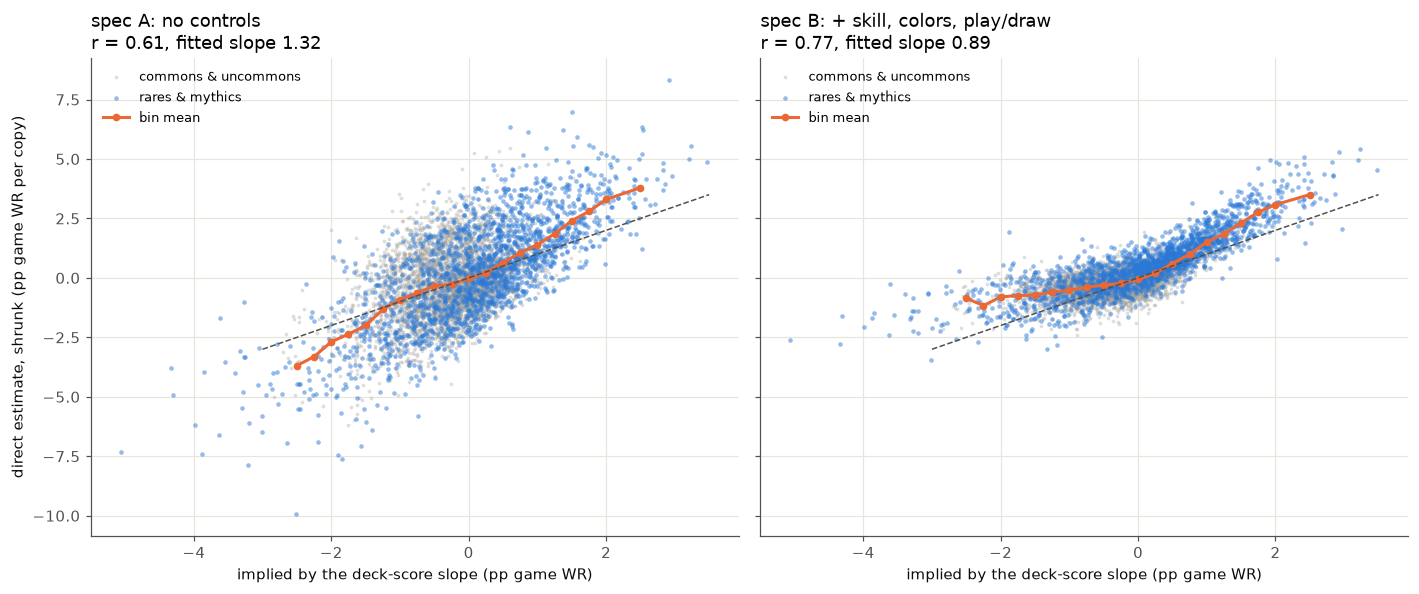

impact_eb_A: cards with implied >= 1.5 pp: 166, mean implied 1.95, mean direct 3.13 (ratio 1.61)
impact: cards with implied >= 1.5 pp: 166, mean implied 1.95, mean direct 2.99 (ratio 1.53)
spec B vs spec A, all cards: mean difference +0.18 pp; correlation 0.71


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
bins = np.arange(-3, 3.51, 0.25)
for ax, (col, lab) in zip(axes, [("impact_eb_A", "spec A: no controls"), ("impact", "spec B: + skill, colors, play/draw")]):
    rare = imp["rarity"].is_in(["rare", "mythic"]).to_numpy()
    ax.scatter(imp["implied"].to_numpy()[~rare], imp[col].to_numpy()[~rare], s=6, color=GRAY, alpha=0.35, lw=0,
               label="commons & uncommons")
    ax.scatter(imp["implied"].to_numpy()[rare], imp[col].to_numpy()[rare], s=9, color=BLUE, alpha=0.5, lw=0,
               label="rares & mythics")
    b = (imp.with_columns(((pl.col("implied") / 0.25).round() * 0.25).alias("bin"))
         .group_by("bin").agg(pl.col(col).mean(), pl.len()).filter(pl.col("len") >= 15).sort("bin"))
    ax.plot(b["bin"], b[col], "o-", color=ORANGE, ms=4, label="bin mean")
    ax.plot([-3, 3.5], [-3, 3.5], color=MUTED, ls="--", lw=1)
    x, y = imp["implied"].to_numpy(), imp[col].to_numpy()
    sl = np.polyfit(x, y, 1)[0]
    ax.set_title(f"{lab}\nr = {np.corrcoef(x, y)[0, 1]:.2f}, fitted slope {sl:.2f}", loc="left")
    ax.set_xlabel("implied by the deck-score slope (pp game WR)")
    ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_ylabel("direct estimate, shrunk (pp game WR per copy)")
plt.tight_layout(); plt.show()

for col in ["impact_eb_A", "impact"]:
    top = imp.filter(pl.col("implied") >= 1.5)
    print(f"{col}: cards with implied >= 1.5 pp: {top.height}, mean implied {top['implied'].mean():.2f}, "
          f"mean direct {top[col].mean():.2f} (ratio {top[col].mean() / top['implied'].mean():.2f})")
print("spec B vs spec A, all cards: mean difference "
      f"{(imp['impact'] - imp['impact_eb_A']).mean():+.2f} pp; correlation {np.corrcoef(imp['impact'], imp['impact_eb_A'])[0, 1]:.2f}")

## 3. The right tail by set

For each set (release order), the 15 highest-impact cards, with 95% intervals from the unshrunk standard error
around the shrunk estimate. Filled markers are on the consensus bomb list (strong or moderate, any timing).
Horizontal lines mark fixed thresholds in pp of game win rate, the same in every set.

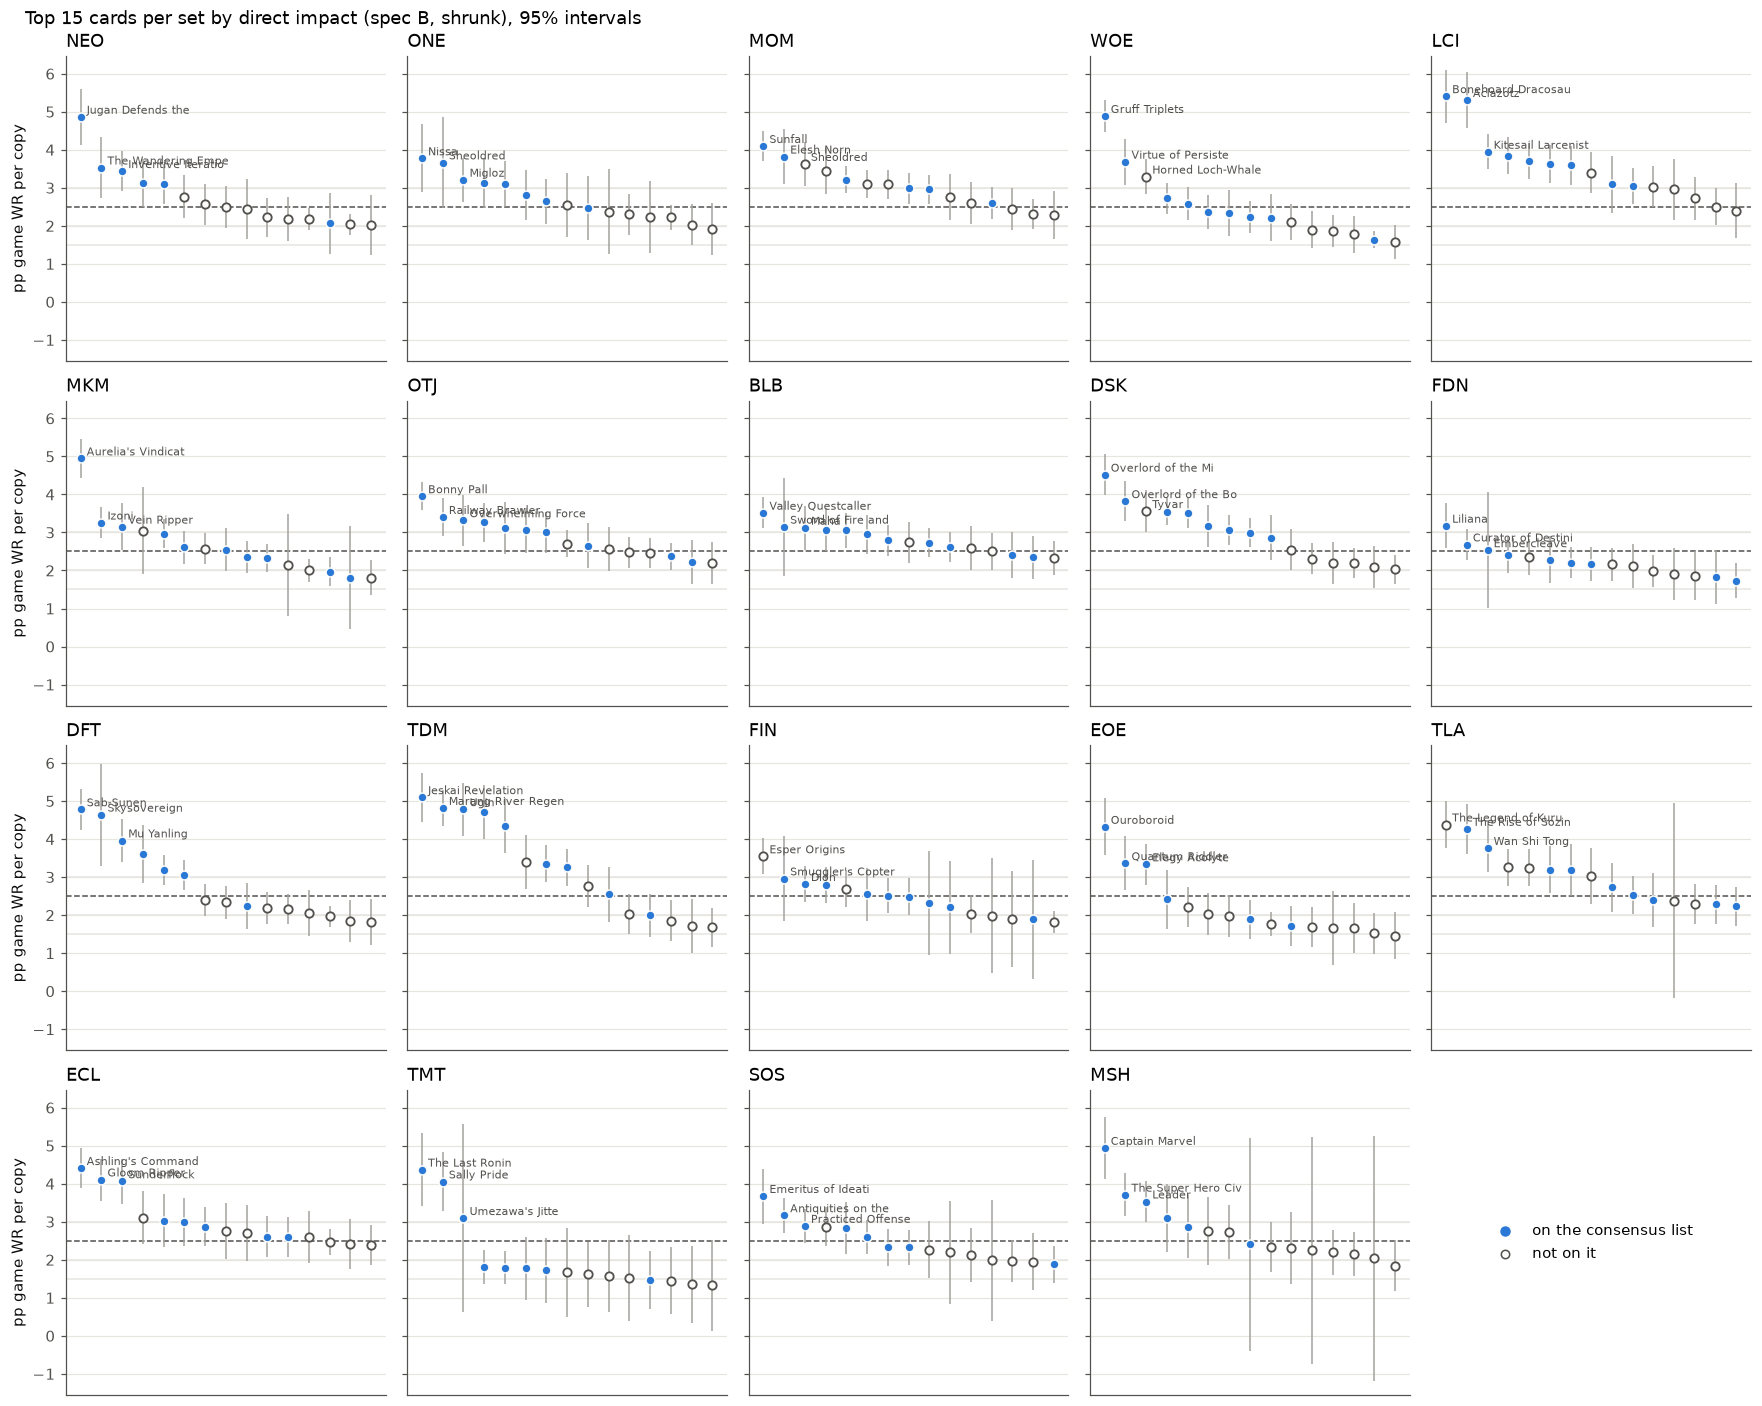

In [4]:
TOP = 15
THRESH = [1.5, 2.0, 2.5, 3.0]
fig, axes = plt.subplots(4, 5, figsize=(16, 13), sharey=True)
for ax, s in zip(axes.flat, SETS):
    d = imp.filter(pl.col("set") == s).sort("impact", descending=True).head(TOP)
    x = np.arange(d.height)
    y, se = d["impact"].to_numpy(), d["se_B"].to_numpy()
    called = d["called"].to_numpy()
    ax.errorbar(x, y, yerr=1.96 * se, fmt="none", ecolor=GRAY, elinewidth=1, capsize=0)
    ax.scatter(x[called], y[called], color=BLUE, s=34, zorder=3, edgecolor=SURFACE, lw=1)
    ax.scatter(x[~called], y[~called], facecolor=SURFACE, edgecolor=MUTED, s=30, zorder=3, lw=1.2)
    for t in THRESH:
        ax.axhline(t, color=GRID if t != 2.5 else MUTED, lw=1, ls="--" if t == 2.5 else "-", zorder=1)
    ax.set_title(s, loc="left"); ax.set_xticks([])
    for xi, yi, n in zip(x[:3], y[:3], d["name"][:3]):
        ax.annotate(n.split(",")[0].split(" //")[0][:18], (xi, yi), xytext=(4, 2), textcoords="offset points",
                    fontsize=7, color=MUTED)
axes.flat[-1].axis("off")
axes.flat[-1].scatter([], [], color=BLUE, s=34, label="on the consensus list")
axes.flat[-1].scatter([], [], facecolor=SURFACE, edgecolor=MUTED, s=30, label="not on it")
axes.flat[-1].legend(loc="center", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("pp game WR per copy")
fig.suptitle(f"Top {TOP} cards per set by direct impact (spec B, shrunk), 95% intervals", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

### 3a. Tail summary per set

* `#1`, `#3`, `#5`, `#10`: the impact of the set's best, 3rd, 5th and 10th best card.
* `≥ 1.5` … `≥ 3.0`: how many cards clear each threshold.
* `fence bombs`: how many cards the bombs notebook's Tukey-fence rule calls bombs, for comparison.

In [5]:
def tail_row(s):
    d = imp.filter(pl.col("set") == s).sort("impact", descending=True)
    v = d["impact"].to_numpy()
    return {"set": s, "cards": d.height, "#1": v[0], "#3": v[2], "#5": v[4], "#10": v[9],
            **{f"≥ {t}": int((v >= t).sum()) for t in THRESH}, "fence bombs": int(d["fence_bomb"].sum())}

tail = pl.DataFrame([tail_row(s) for s in SETS])
tail.write_csv(BOMBS / "card_impact_tail.csv")
display(tail)
print("median over sets:", {k: round(float(tail[k].median()), 2) for k in tail.columns[2:]})
print("total over sets:", {k: int(tail[k].sum()) for k in tail.columns[6:]})

set,cards,#1,#3,#5,#10,≥ 1.5,≥ 2.0,≥ 2.5,≥ 3.0,fence bombs
str,i64,f64,f64,f64,f64,i64,i64,i64,i64,i64
"""NEO""",280,4.87,3.44,3.10,2.22,27,15,7,5,5
"""ONE""",260,3.77,3.21,3.10,2.37,22,14,8,5,2
"""MOM""",341,4.10,3.63,3.22,2.75,34,21,12,7,7
"""WOE""",307,4.89,3.29,2.58,2.09,15,10,5,3,2
"""LCI""",285,5.41,3.95,3.70,3.06,31,22,14,11,10
"""MKM""",301,4.95,3.15,2.97,2.32,23,12,8,4,3
"""OTJ""",368,3.95,3.32,3.11,2.57,26,16,10,7,8
"""BLB""",267,3.52,3.12,3.06,2.62,25,18,12,5,6
"""DSK""",274,4.52,3.56,3.51,2.54,25,16,10,7,8


median over sets: {'#1': 4.38, '#3': 3.33, '#5': 3.06, '#10': 2.32, '≥ 1.5': 22.0, '≥ 2.0': 14.0, '≥ 2.5': 8.0, '≥ 3.0': 5.0, 'fence bombs': 3.0}
total over sets: {'≥ 1.5': 444, '≥ 2.0': 262, '≥ 2.5': 153, '≥ 3.0': 96, 'fence bombs': 91}


### 3b. The pooled right tail

All 19 sets on one axis: the number of cards above each impact level, per set as thin lines and the median set
thick. A set whose line sits higher has more high-impact cards.

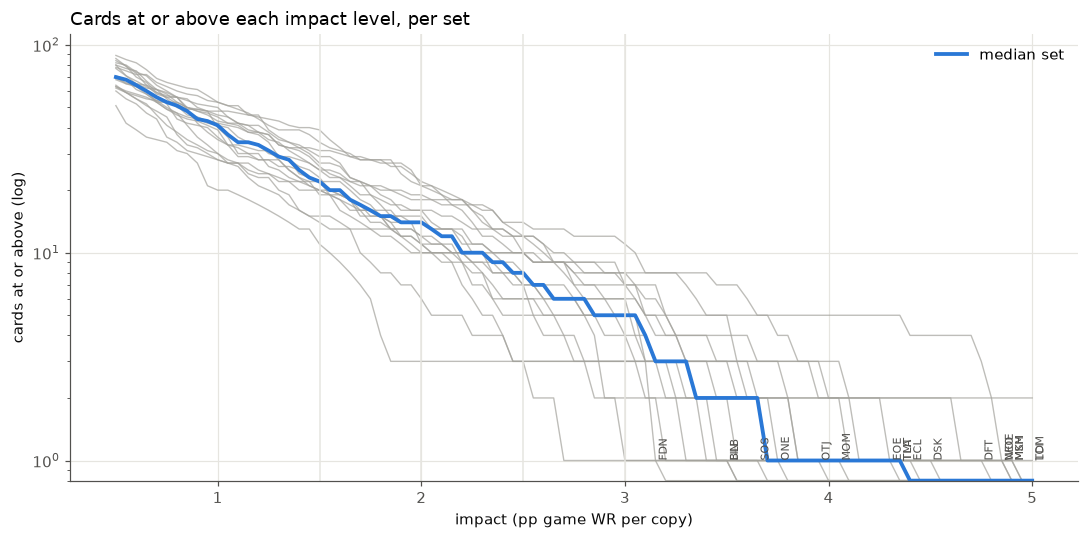

In [6]:
lv = np.linspace(0.5, 5, 91)
fig, ax = plt.subplots(figsize=(10, 5))
curves = []
for s in SETS:
    v = imp.filter(pl.col("set") == s)["impact"].to_numpy()
    c = np.array([(v >= t).sum() for t in lv]); curves.append(c)
    ax.plot(lv, np.maximum(c, 0.8), color=GRAY, lw=0.9, alpha=0.7)
    i = np.searchsorted(-c, -1, side="right") - 1
    if c[0] > 0:
        last = lv[c > 0].max()
        ax.annotate(s, (last, 1), xytext=(2, 0), textcoords="offset points", fontsize=7, color=MUTED, rotation=90, va="bottom")
ax.plot(lv, np.maximum(np.median(curves, 0), 0.8), color=BLUE, lw=2.5, label="median set")
ax.set_yscale("log"); ax.set_ylim(0.8, None)
ax.set_xlabel("impact (pp game WR per copy)"); ax.set_ylabel("cards at or above (log)")
for t in THRESH:
    ax.axvline(t, color=GRID, lw=1)
ax.set_title("Cards at or above each impact level, per set", loc="left"); ax.legend()
plt.tight_layout(); plt.show()

### 3c. Is the per-set slope a ruler or a real difference?

The deck-score slope is smaller in sets where deck scores spread wider (bombs notebook, section 2b″). There are two readings:

* **Ruler.** Ratings are stretched (or noisier) in some sets, and the slope just converts them back. Then the
  real worth of the top cards, measured directly in pp of game WR, shouldn't track the slope or the score spread.
* **Real.** In wide-spread sets each card really moves win rate less. Then the direct impact of the top
  cards should be lower where `sd drafter` is high, and track the slope.

Per set, the direct impact of the 1st, 5th and 10th best card, and the mean of the top 10, correlated across the 19
sets with the set's `sd drafter` (bombs notebook), its slope, and the rating of its 5th best card in pp.

top-card value,r with sd drafter,p (sd drafter),r with slope,p (slope)
str,f64,f64,f64,f64
"""#1""",0.025,0.918,-0.005,0.983
"""#5""",-0.028,0.911,-0.095,0.700
"""#10""",0.150,0.541,-0.086,0.726
"""top-10 mean""",0.025,0.920,-0.062,0.800
"""rating #5""",0.012,0.961,-0.181,0.459


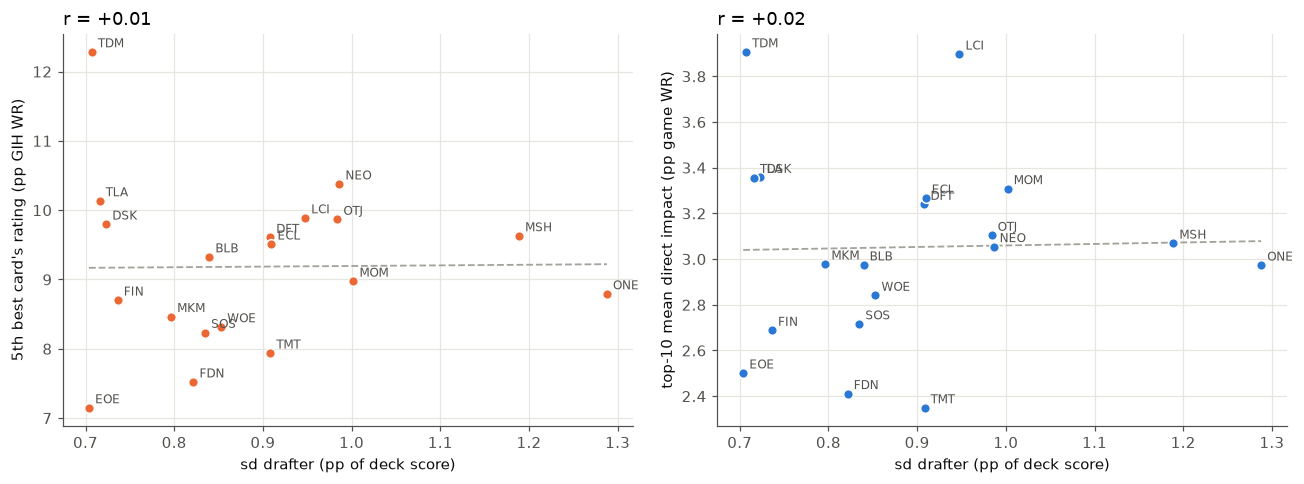

In [7]:
from scipy.stats import pearsonr
summ = pl.read_csv(BOMBS / "deck_score_summary_gih.csv").select("set", "sd drafter", "slope")
rows = []
for s in SETS:
    d = imp.filter(pl.col("set") == s).sort("impact", descending=True)
    r5 = imp.filter(pl.col("set") == s).sort("norm_eb", descending=True)["norm_eb"][4]
    rows.append({"set": s, "#1": d["impact"][0], "#5": d["impact"][4], "#10": d["impact"][9],
                 "top-10 mean": d["impact"].head(10).mean(), "rating #5": r5})
rt = pl.DataFrame(rows).join(summ, on="set")
out = []
for y in ["#1", "#5", "#10", "top-10 mean", "rating #5"]:
    row = {"top-card value": y}
    for x in ["sd drafter", "slope"]:
        r, p = pearsonr(rt[x], rt[y]); row[f"r with {x}"] = r; row[f"p ({x})"] = p
    out.append(row)
with pl.Config(float_precision=3):
    display(pl.DataFrame(out))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, (y, lab, c) in zip(axes, [("rating #5", "5th best card's rating (pp GIH WR)", ORANGE),
                                  ("top-10 mean", "top-10 mean direct impact (pp game WR)", BLUE)]):
    ax.scatter(rt["sd drafter"], rt[y], color=c, s=40, edgecolor=SURFACE, lw=1, zorder=3)
    for s, xi, yi in zip(rt["set"], rt["sd drafter"], rt[y]):
        ax.annotate(s, (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=8, color=MUTED)
    b, a = np.polyfit(rt["sd drafter"], rt[y], 1)
    xx = np.linspace(rt["sd drafter"].min(), rt["sd drafter"].max(), 2)
    ax.plot(xx, a + b * xx, color=GRAY, ls="--", lw=1.2)
    ax.set_xlabel("sd drafter (pp of deck score)"); ax.set_ylabel(lab)
    ax.set_title(f"r = {pearsonr(rt['sd drafter'], rt[y])[0]:+.2f}", loc="left")
plt.tight_layout(); plt.show()

## 4. Against the consensus bomb list

The consensus list (`results/bombs/consensus_bombs.csv`, groups as in `notebooks/consensus_bombs.ipynb`) next to the
direct impact. First the distribution of impact by group, then how well impact separates "called a bomb" from the
other rares and mythics. That's the AUC: the chance that a random called bomb has a higher value than a random other
rare or mythic, pooled across sets. It's computed for direct impact and for the rating, for comparison. Then the card lists.

group,cards,median impact,q25,q75,median implied,median rank,share ≥ 2.0,share ≥ 2.5
str,u32,f64,f64,f64,f64,f64,f64,f64
"""bomb: pre & post""",92,3.06,2.40,3.59,1.67,5.00,0.89,0.72
"""bomb: post only""",52,2.92,2.28,3.40,1.67,5.50,0.75,0.63
"""bomb: pre only""",44,2.18,1.58,2.65,1.36,11.50,0.55,0.34
"""hyped, downgraded""",28,0.94,0.71,1.51,0.70,38.00,0.14,0.00
"""other rare/mythic""",1637,0.31,-0.36,0.98,0.03,94.00,0.06,0.02
"""uncommon""",1899,-0.01,-0.38,0.40,-0.21,136.00,0.00,0.00
"""common""",1779,-0.38,-0.68,-0.08,-0.31,197.00,0.00,0.00


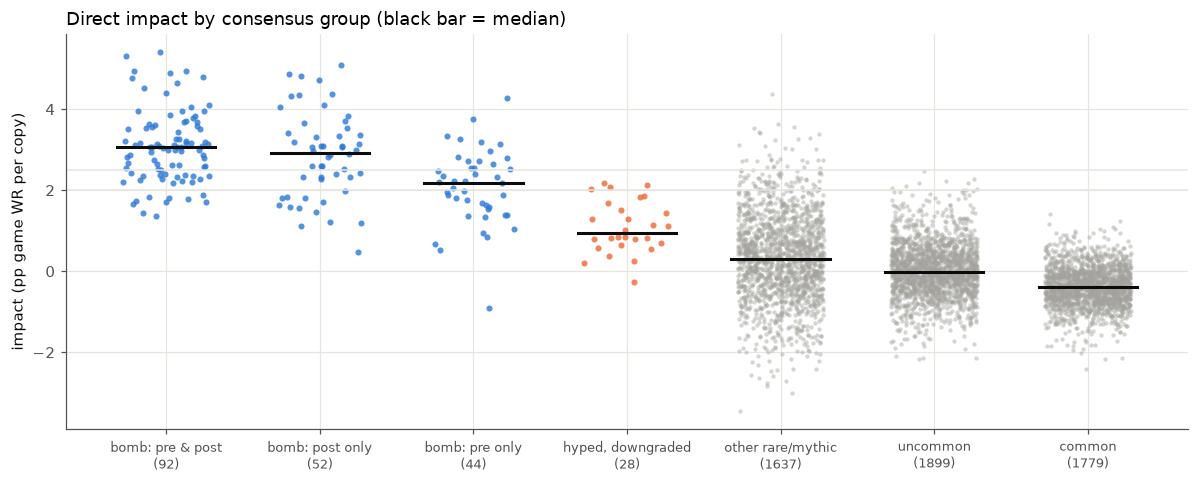

AUC, called bombs vs other rares/mythics, by direct impact: 0.956
AUC, called bombs vs other rares/mythics, by rating (via shortcut): 0.962


In [8]:
GROUPS = ["bomb: pre & post", "bomb: post only", "bomb: pre only", "hyped, downgraded", "other rare/mythic", "uncommon", "common"]
gs = (imp.filter(pl.col("group").is_in(GROUPS)).group_by("group").agg(
        pl.len().alias("cards"), pl.col("impact").median().alias("median impact"),
        pl.col("impact").quantile(0.25).alias("q25"), pl.col("impact").quantile(0.75).alias("q75"),
        pl.col("implied").median().alias("median implied"), pl.col("impact_rank").median().alias("median rank"),
        (pl.col("impact") >= 2.0).mean().alias("share ≥ 2.0"), (pl.col("impact") >= 2.5).mean().alias("share ≥ 2.5"))
      .sort(pl.col("group").replace_strict({g: i for i, g in enumerate(GROUPS)})))
display(gs)

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, g in enumerate(GROUPS):
    v = imp.filter(pl.col("group") == g)["impact"].to_numpy()
    jit = np.random.default_rng(i).uniform(-0.28, 0.28, len(v))
    c = BLUE if g.startswith("bomb") else ORANGE if g.startswith("hyped") else GRAY
    ax.scatter(i + jit, v, s=8 if len(v) > 300 else 16, color=c, alpha=0.45 if len(v) > 300 else 0.8, lw=0)
    ax.plot([i - 0.32, i + 0.32], [np.median(v)] * 2, color=INK, lw=2)
ax.set_xticks(range(len(GROUPS)), [f"{g}\n({imp.filter(pl.col('group') == g).height})" for g in GROUPS], fontsize=8.5)
ax.set_ylabel("impact (pp game WR per copy)")
for t in [2.0, 2.5]:
    ax.axhline(t, color=GRID, lw=1)
ax.set_title("Direct impact by consensus group (black bar = median)", loc="left")
plt.tight_layout(); plt.show()

rm = imp.filter(pl.col("rarity").is_in(["rare", "mythic"]) & pl.col("group").is_in(GROUPS))
for col, lab in [("impact", "direct impact"), ("implied", "rating (via shortcut)")]:
    a = rm.filter(pl.col("called"))[col].to_numpy(); b = rm.filter(pl.col("group") == "other rare/mythic")[col].to_numpy()
    auc = mannwhitneyu(a, b).statistic / (len(a) * len(b))
    print(f"AUC, called bombs vs other rares/mythics, by {lab}: {auc:.3f}")

### 4a. Per set: does the list match the top of the impact ranking?

* `called`: consensus cards (strong or moderate) with an estimate.
* `in top 5 / top 10`: how many of the set's top 5 / top 10 cards by impact are on the list.
* `called ≥ 2.0`: how many of the called cards clear 2.0 pp.
* `median rank`: the called cards' median rank in the set by impact.
* `Spearman`: within the set's rares and mythics, rank correlation of impact with rating (do the two orderings agree?).

In [9]:
rows = []
for s in SETS:
    d = imp.filter(pl.col("set") == s)
    c = d.filter(pl.col("called"))
    top10 = d.sort("impact", descending=True).head(10)
    rmy = d.filter(pl.col("rarity").is_in(["rare", "mythic"]))
    rows.append({"set": s, "called": c.height, "in top 5": int(top10.head(5)["called"].sum()),
                 "in top 10": int(top10["called"].sum()), "called ≥ 2.0": int((c["impact"] >= 2.0).sum()),
                 "median rank": c["impact_rank"].median(),
                 "Spearman": spearmanr(rmy["impact"], rmy["norm_eb"])[0]})
per = pl.DataFrame(rows)
display(per)
print("totals:", {k: int(per[k].sum()) for k in ["called", "in top 5", "in top 10", "called ≥ 2.0"]},
      f"of {5 * len(SETS)} top-5 and {10 * len(SETS)} top-10 slots")

set,called,in top 5,in top 10,called ≥ 2.0,median rank,Spearman
str,i64,i64,i64,i64,f64,f64
"""NEO""",7,5,5,6,4.00,0.85
"""ONE""",10,5,8,8,5.50,0.88
"""MOM""",8,3,5,6,8.50,0.92
"""WOE""",11,4,8,8,7.00,0.88
"""LCI""",9,5,9,9,5.00,0.90
"""MKM""",11,4,8,8,8.00,0.93
"""OTJ""",13,5,8,10,7.00,0.88
"""BLB""",12,5,9,12,6.50,0.92
"""DSK""",8,4,8,8,5.50,0.95


totals: {'called': 188, 'in top 5': 81, 'in top 10': 137, 'called ≥ 2.0': 145} of 95 top-5 and 190 top-10 slots


### 4b. The cards

Every set's top cards by impact (≥ 2.0 pp) plus every consensus card, with:

* `impact` ± `se`: the direct estimate (shrunk) and its unshrunk standard error, pp of game WR per copy.
* `implied`: what the rating says via the slope shortcut.
* `rank`: rank in the set by impact (`rating rank`: by GIH WR rating).
* `group`: consensus group; `fence`: whether the bombs notebook's Tukey rule calls it a bomb.

Saved as `results/bombs/card_impact_vs_consensus.csv`.

In [10]:
lst = (imp.filter((pl.col("impact") >= 2.0) | pl.col("agreement").is_not_null())
       .sort(pl.col("set").replace_strict({s: i for i, s in enumerate(SETS)}), pl.col("impact"), descending=[False, True])
       .select("set", "name", "rarity", "impact", pl.col("se_B").alias("se"), "implied",
               pl.col("impact_rank").alias("rank"), pl.col("rating_rank").alias("rating rank"), "group",
               pl.col("fence_bomb").alias("fence"), "games_in_deck"))
lst.write_csv(BOMBS / "card_impact_vs_consensus.csv")
with pl.Config(tbl_rows=500, fmt_str_lengths=40):
    display(lst.drop("games_in_deck"))

set,name,rarity,impact,se,implied,rank,rating rank,group,fence
str,str,str,f64,f64,f64,i64,i64,str,bool
"""NEO""","""Jugan Defends the Temple""","""mythic""",4.87,0.38,2.01,1,1,"""bomb: post only""",true
"""NEO""","""The Wandering Emperor""","""mythic""",3.53,0.41,1.74,2,3,"""bomb: pre & post""",true
"""NEO""","""Inventive Iteration""","""rare""",3.44,0.26,1.59,3,4,"""bomb: pre & post""",true
"""NEO""","""Farewell""","""rare""",3.13,0.32,1.59,4,5,"""bomb: post only""",true
"""NEO""","""Fable of the Mirror-Breaker""","""rare""",3.10,0.27,1.81,5,2,"""bomb: post only""",true
"""NEO""","""Kami of Transience""","""rare""",2.77,0.28,0.97,6,22,"""other rare/mythic""",false
"""NEO""","""Reckoner Bankbuster""","""rare""",2.56,0.27,1.19,7,10,"""other rare/mythic""",false
"""NEO""","""Invoke the Ancients""","""rare""",2.49,0.28,1.36,8,6,"""other rare/mythic""",false
"""NEO""","""Kura, the Boundless Sky""","""mythic""",2.44,0.40,1.00,9,20,"""other rare/mythic""",false


### 4c. High impact, not on the list; on the list, low impact

Cards ≥ 2.5 pp that the consensus list doesn't call a bomb, and called bombs below 1.5 pp.

In [11]:
with pl.Config(tbl_rows=200, fmt_str_lengths=40):
    print("High impact (≥ 2.5 pp), not called a bomb")
    display(lst.filter((pl.col("impact") >= 2.5) & ~pl.col("group").str.starts_with("bomb")).drop("games_in_deck"))
    print("Called a bomb, impact < 1.5 pp")
    display(lst.filter((pl.col("impact") < 1.5) & pl.col("group").str.starts_with("bomb")).drop("games_in_deck"))

High impact (≥ 2.5 pp), not called a bomb


set,name,rarity,impact,se,implied,rank,rating rank,group,fence
str,str,str,f64,f64,f64,i64,i64,str,bool
"""NEO""","""Kami of Transience""","""rare""",2.77,0.28,0.97,6,22,"""other rare/mythic""",false
"""NEO""","""Reckoner Bankbuster""","""rare""",2.56,0.27,1.19,7,10,"""other rare/mythic""",false
"""ONE""","""Elesh Norn, Mother of Machines""","""mythic""",2.55,0.43,1.01,8,10,"""weak mention""",false
"""MOM""","""Sheoldred""","""mythic""",3.63,0.29,1.50,3,6,"""other rare/mythic""",true
"""MOM""","""Vorinclex""","""mythic""",3.44,0.31,1.44,4,10,"""other rare/mythic""",false
"""MOM""","""Zephyr Singer""","""rare""",3.09,0.19,1.50,6,5,"""other rare/mythic""",true
"""MOM""","""Glissa, Herald of Predation""","""rare""",3.09,0.20,1.47,7,7,"""weak mention""",true
"""MOM""","""Chandra, Hope's Beacon""","""mythic""",2.75,0.31,1.47,10,8,"""other rare/mythic""",false
"""MOM""","""Invasion of New Phyrexia""","""mythic""",2.61,0.28,1.43,11,11,"""weak mention""",false


Called a bomb, impact < 1.5 pp


set,name,rarity,impact,se,implied,rank,rating rank,group,fence
str,str,str,f64,f64,f64,i64,i64,str,bool
"""ONE""","""Atraxa, Grand Unifier""","""mythic""",0.48,0.75,0.97,71,14,"""bomb: post only""",false
"""MOM""","""Elesh Norn""","""mythic""",0.67,0.31,0.39,76,67,"""bomb: pre only""",false
"""WOE""","""The Goose Mother""","""rare""",1.36,0.23,1.25,18,13,"""bomb: pre only""",false
"""WOE""","""Goblin Bombardment""","""rare""",0.85,0.30,1.25,32,12,"""bomb: pre only""",false
"""MKM""","""Teysa, Opulent Oligarch""","""rare""",1.36,0.23,1.46,28,12,"""bomb: pre & post""",false
"""OTJ""","""Terror of the Peaks""","""mythic""",1.34,0.29,0.71,33,31,"""bomb: pre only""",false
"""FDN""","""Chandra, Flameshaper""","""mythic""",1.43,0.32,1.45,23,12,"""bomb: pre & post""",false
"""TDM""","""Ambling Stormshell""","""rare""",1.04,0.24,0.79,28,22,"""bomb: pre only""",false
"""FIN""","""Yawgmoth, Thran Physician""","""mythic""",1.40,0.67,1.53,23,17,"""bomb: pre only""",false
